Device: cpu


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

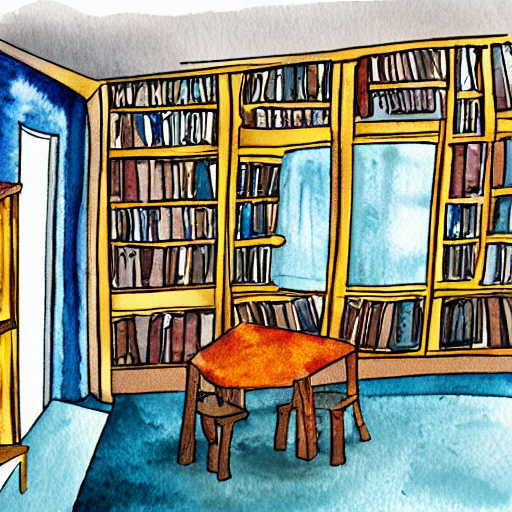

  0%|          | 0/25 [00:00<?, ?it/s]

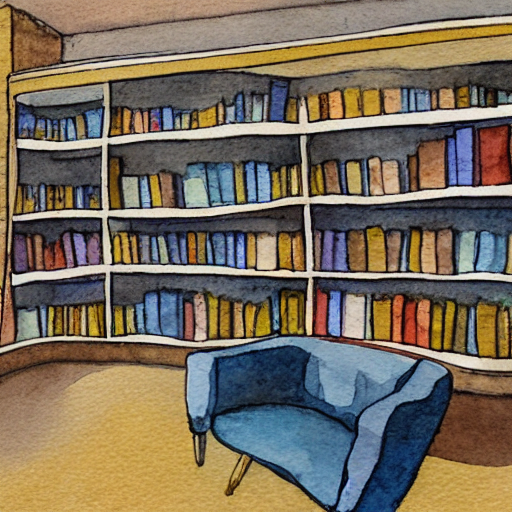

  0%|          | 0/25 [00:00<?, ?it/s]

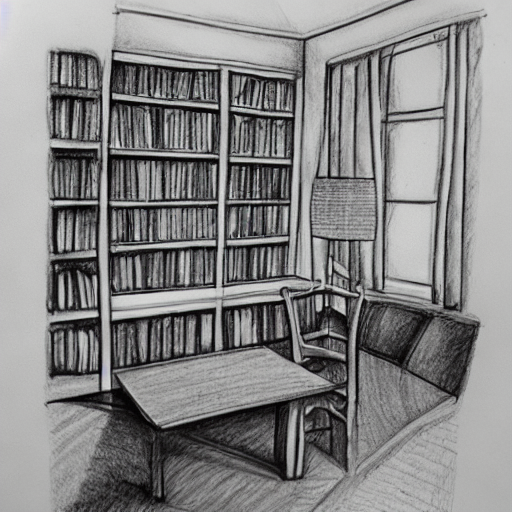

  0%|          | 0/25 [00:00<?, ?it/s]

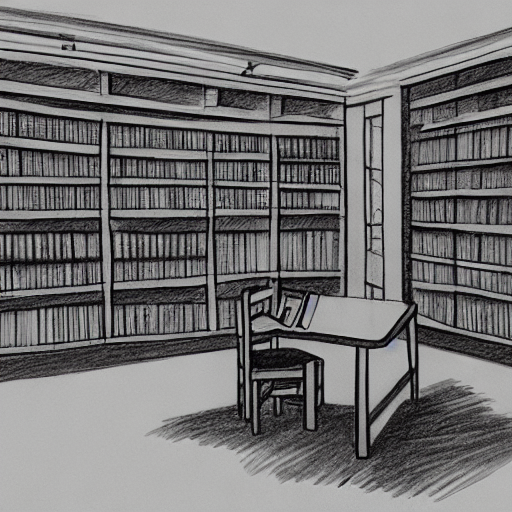

In [1]:
# Lab 4 (CPU version): Stable Diffusion prompt comparison


from pathlib import Path
import random
import torch

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
out = Path("lab_outputs")
out.mkdir(exist_ok=True)
print("Device:", device)

from diffusers import StableDiffusionPipeline
from IPython.display import display

repo = "stable-diffusion-v1-5/stable-diffusion-v1-5"
dtype = torch.float16 if device.type == "cuda" else torch.float32
pipe = StableDiffusionPipeline.from_pretrained(repo, torch_dtype=dtype)
pipe = pipe.to(device)
pipe.enable_attention_slicing()

prompts = [
    "A small library with a reading table, wide view, watercolor illustration",
    "A small library with a reading table, wide view, pencil sketch",
]

for i, prompt in enumerate(prompts, 1):
    for seed in (42, 43):
        rng = torch.Generator(device=device).manual_seed(seed)
        result = pipe(prompt, width=512, height=512,
                      num_inference_steps=25, guidance_scale=7.5, generator=rng)
        flags = result.nsfw_content_detected
        if flags and flags[0]:
            print("Image flagged. Review the classroom prompt.")
            continue
        image = result.images[0]
        image.save(out / f"library_prompt_{i}_seed_{seed}.png")
        display(image)